# Question answering

Question Answering (QA), o respuesta automática a preguntas, es una tarea del Procesamiento de Lenguaje Natural (NLP) cuyo objetivo consiste en desarrollar sistemas capaces de responder preguntas formuladas por usuarios utilizando información proveniente de documentos, bases de datos, textos, sitios web o modelos de conocimiento.


## Entrada: pregunta del usuario

  * ¿Cuál es la capital de Francia?


## Procesamiento del lenguaje natural

  * Tokenización, análisis semántico, identificación de intención y entidades.

## Recuperación o inferencia

*  Buscar información en documentos, bases de conocimiento o utilizar un modelo entrenado.


## Respuesta
  * París.



| Tipo               | Descripción                                                                   | Ejemplo                                     |
|--------------------|-------------------------------------------------------------------------------|---------------------------------------------|
| Extractive QA      | Extraer literalmente la respuesta de un texto.                                | Identificar una fecha en un documento.      |
| Abstractive QA     | Generar una respuesta mediante una reformulación del conocimiento disponible. | Resumir una explicación.                    |
| Open-domain QA     | Responder preguntas sobre conocimiento general.                               | ¿Qué es una red neuronal?                   |
| Closed-domain QA   | Responder preguntas dentro de un dominio específico.                          | Preguntas sobre reglamentos universitarios. |
| Knowledge-based QA | Consultar bases de conocimiento estructuradas.                                | ¿Qué materias pertenecen a un semestre?     |
| Conversational QA  | Mantener el contexto entre preguntas sucesivas.                               | ¿Cuándo se fundó? ¿Y quién fue su fundador? |

# Extractive vs. Abstractive QA
Considerar el siguiente documento:
> La Universidad Tecnológica de la Mixteca fue fundada en 1990 y se encuentra en Huajuapan de León, Oaxaca.


**¿En qué año fue fundada la universidad?**
- Extractive QA: "1990".
- Abstractive QA: "La universidad inició sus actividades en el año 1990".

## Técnicas y modelos se utilizan:

Puede implementarse mediante diferentes técnicas de ML y Deep Learning.

| Técnica          | Aplicación                                 |
|------------------|--------------------------------------------|
| TF-IDF           | Recuperación de documentos relevantes.     |
| Word Embeddings  | Representación vectorial de palabras.      |
| Word2Vec / GloVe | Capturar relaciones semánticas.            |
| RNN / LSTM       | Procesamiento secuencial del lenguaje.     |
| Transformers     | Comprensión contextual del lenguaje.       |
| BERT             | Principalmente Extractive QA.              |
| T5               | Generación de respuestas.                  |
| GPT              | Respuestas generativas y conversacionales. |



## Modelos relevantes:
- **[BERT](https://arxiv.org/abs/1810.04805)**: permite identificar fragmentos de texto que contienen respuestas.
- **[RoBERTa](https://arxiv.org/abs/1907.11692)**: variante optimizada de BERT.
- **[T5](https://research.google/blog/exploring-transfer-learning-with-t5-the-text-to-text-transfer-transformer/)**: transforma tareas NLP en problemas de texto a texto.
- **[Flan-T5](https://huggingface.co/docs/transformers/v5.24.0/en/model_doc/flan-t5?utm_source=chatgpt.com)**: entrenado para seguir instrucciones y responder preguntas.

# Question Answering y RAG
Una de las arquitecturas más importantes actualmente es Retrieval-Augmented Generation (RAG).

RAG combina dos procesos:
1. **Retrieval**: recuperar documentos o fragmentos de información relacionados con la pregunta.
2. **Generation**: utilizar un LLM para generar una respuesta basada en la información recuperada.

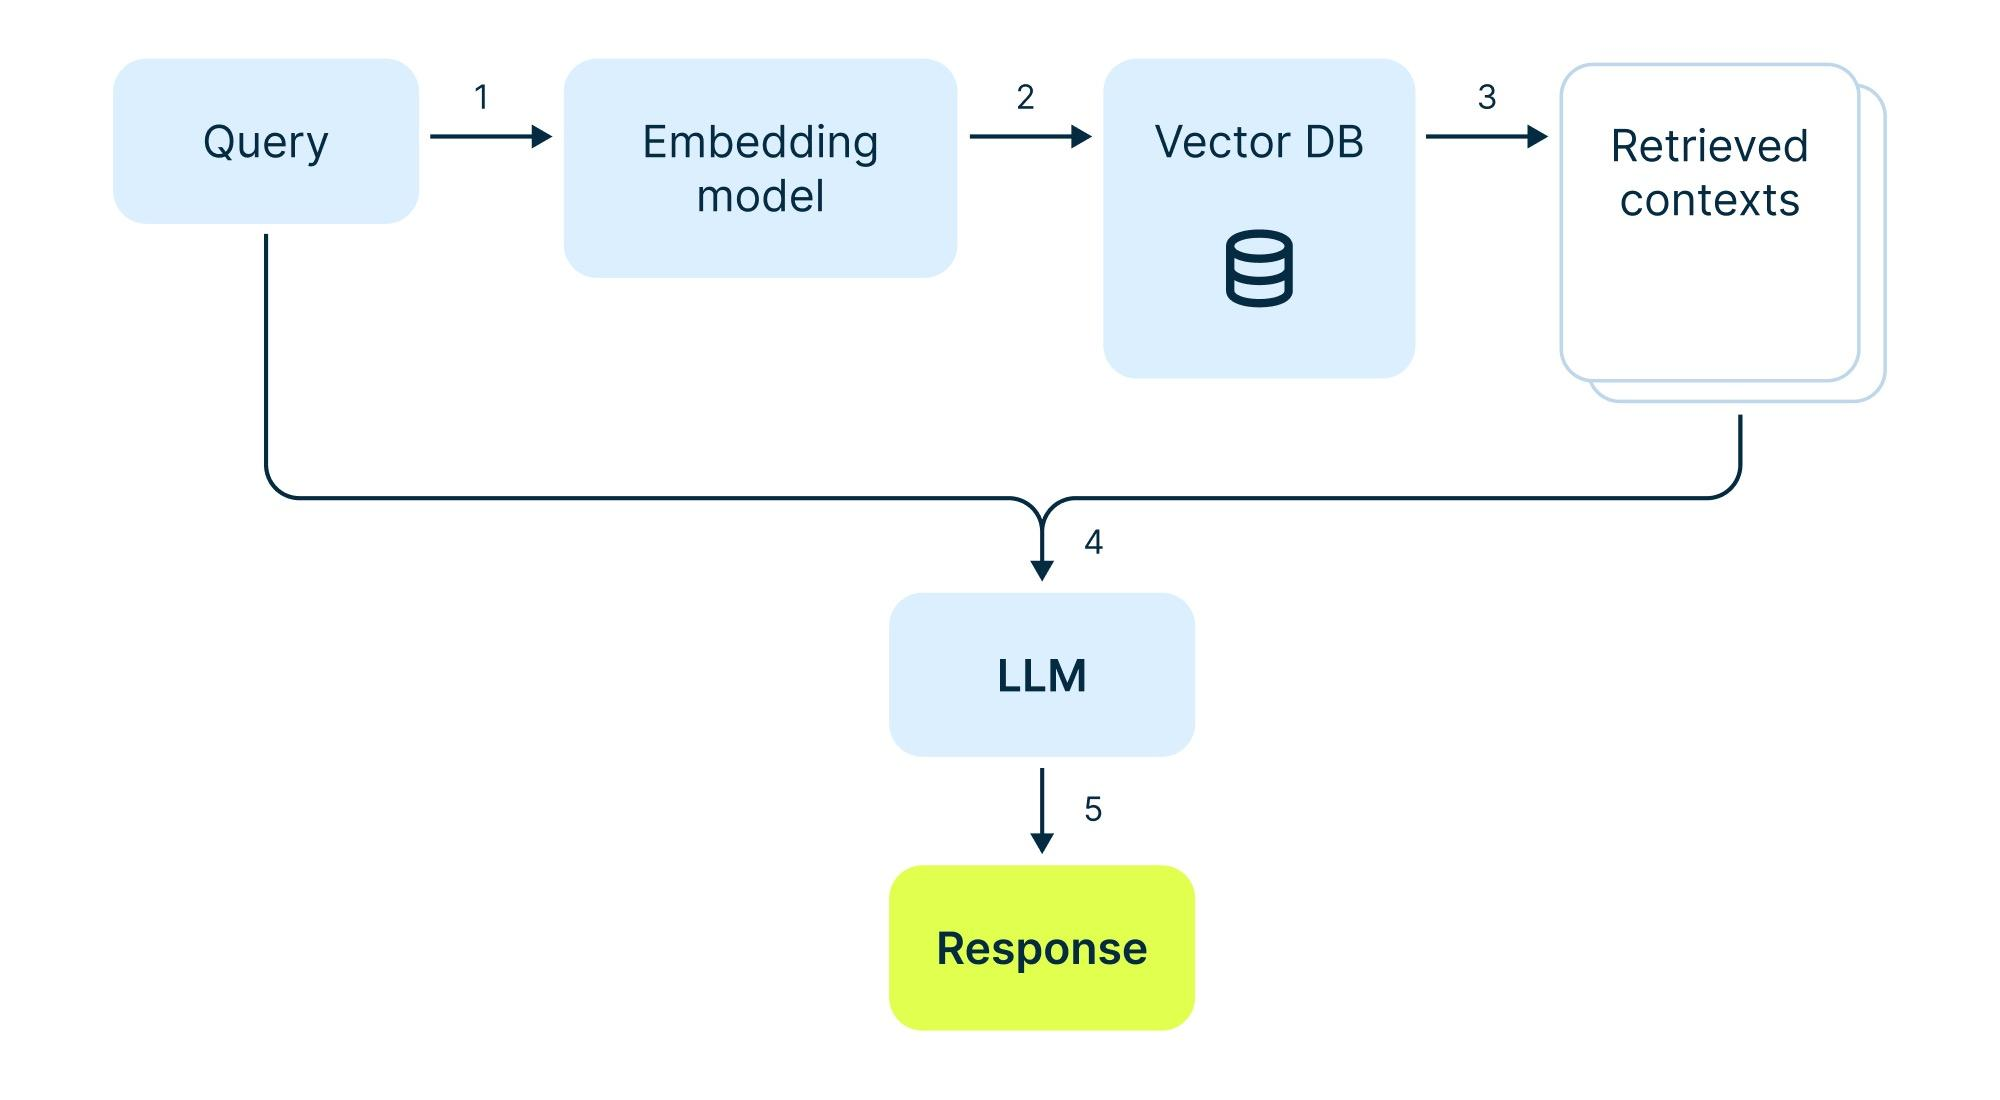

## ¿Cómo evaluar un sistema Question Answering?
La evaluación depende del tipo de QA implementado.


| Métrica          | Descripción                                                                        |
|------------------|------------------------------------------------------------------------------------|
| Exact Match (EM) | Porcentaje de respuestas que coinciden exactamente con la respuesta esperada.      |
| F1 Score         | Evalúa la coincidencia entre tokens de la respuesta generada y la esperada.        |
| BLEU             | Evalúa similitud mediante coincidencias de secuencias de palabras.                 |
| ROUGE            | Evalúa coincidencias de unidades textuales, especialmente en generación y resumen. |
| BERTScore        | Compara similitud semántica mediante representaciones contextuales.                |

# Extractive QA

In [1]:
import torch
from transformers import DistilBertTokenizerFast, AutoModelForQuestionAnswering

# Usamos el tokenizador específico rápido para evitar fallos de mapeo dinámico
model_name = "distilbert-base-cased-distilled-squad"
tokenizer = DistilBertTokenizerFast.from_pretrained(model_name)
model = AutoModelForQuestionAnswering.from_pretrained(model_name)

def qa_pipeline(question, context):
    # Tokenizar las entradas preparándolas para el modelo de QA
    inputs = tokenizer(question, context, return_tensors="pt")

    # Obtener las predicciones (logits) de inicio y fin de la respuesta
    with torch.no_grad():
        outputs = model(**inputs)

    # Extraer los índices con mayor probabilidad
    answer_start_index = outputs.start_logits.argmax()
    answer_end_index = outputs.end_logits.argmax() + 1

    # Decodificar el fragmento extraído del contexto original
    predict_answer_tokens = inputs.input_ids[0, answer_start_index : answer_end_index]
    answer = tokenizer.decode(predict_answer_tokens)
    return {"answer": answer}

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/473 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  261MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

In [2]:
context = """The Amazon rainforest is the largest tropical rainforest in the world,
covering parts of Brazil, Peru, and Colombia.
"""

question = "Which countries does the Amazon rainforest cover?"
qa_answer = qa_pipeline(question=question, context=context)

print(qa_answer)

{'answer': 'Brazil, Peru, and Colombia'}


# Abstractive QA

In [3]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch

# Cargamos un modelo de generación (Seq2Seq) optimizado para seguir instrucciones
abstractive_model_name = "google/flan-t5-base"
abs_tokenizer = AutoTokenizer.from_pretrained(abstractive_model_name)
abs_model = AutoModelForSeq2SeqLM.from_pretrained(abstractive_model_name)

def abstractive_qa(question, context):
    # Estructuramos el prompt en formato de instrucción
    prompt = f"Answer the following question based on the context.\nQuestion: {question}\nContext: {context}"

    inputs = abs_tokenizer(prompt, return_tensors="pt")

    with torch.no_grad():
        outputs = abs_model.generate(**inputs, max_length=100)

    answer = abs_tokenizer.decode(outputs[0], skip_special_tokens=True)
    return {"answer": answer}

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

In [8]:
context = """The Amazon rainforest is the largest tropical rainforest in the world,
covering parts of Brazil, Peru, and Colombia.
"""
question = "Which countries does the Amazon rainforest cover?"

# Obtener respuesta abstractiva
abs_answer = abstractive_qa(question=question, context=context)
print("Abstractive QA:", abs_answer)

Abstractive QA: {'answer': 'Brazil, Peru, and Colombia'}


### Forzando un comportamiento más Abstractivo y Conversacional
Se usa un prompt para guiar al modelo a generar una respuesta completa, redactada con conectores naturales en lugar de limitarse a extraer las palabras clave.

In [12]:
def abstractive_qa_conversational(question, context):
    # Prompt modificado con instrucciones explícitas de estilo
    prompt = (
        f"Using the context provided, write a complete, natural-sounding sentence "
        f"that answers the question in detail.\n\n"
        f"Context: {context}\n"
        f"Question: {question}\n"
        f"Answer:"
    )

    inputs = abs_tokenizer(prompt, return_tensors="pt")

    with torch.no_grad():
        # parámetros de generación para dar más libertad creativa y longitud
        outputs = abs_model.generate(
            **inputs,
            max_length=150,
            min_length=10,       # longitud mínima
            do_sample=True,      # Activa muestreo para evitar respuestas directas
            temperature=0.7,     # Control de creatividad
            top_k=50
        )

    answer = abs_tokenizer.decode(outputs[0], skip_special_tokens=True)
    return {"answer": answer}


In [ ]:
conversational_answer = abstractive_qa_conversational(question, context)
print("Abstractive QA:", conversational_answer)

In [15]:
context = """La arquitectura de computadoras se divide principalmente en dos filosofías de diseño de conjuntos de instrucciones:
CISC (Complex Instruction Set Computer) y RISC (Reduced Instruction Set Computer). Los procesadores CISC, representados históricamente por la familia x86 de Intel y AMD, se caracterizan por contar con un repertorio amplio y complejo de instrucciones capaces de ejecutar múltiples operaciones de bajo nivel en una sola línea de código máquina, como leer de memoria, realizar un cálculo aritmético y escribir el resultado. Este enfoque reduce el trabajo del compilador y minimiza la cantidad de líneas de código necesarias en un programa, aunque exige circuitos de decodificación más complejos y un mayor consumo energético.
"""


question = "¿Qué arquitectura requiere un mayor número de instrucciones en un programa y compiladores más sofisticados?"


In [16]:
conversational_answer = abstractive_qa_conversational(question, context)
print("Abstractive QA:", conversational_answer)

Abstractive QA: {'answer': 'The architecture of computadoras is primarily based on two filosofas of design: CISC (Complex Instruction Set Computer) and RISC (Reduced Instruction Set Computer). The processors CISC, represented historically by the x86 family of Intel and AMD, are characterized by having a large and complex repertory and complex instrucciones capable of ejecting multiple operations sub-level in a single line of código máquina, like reading memory, making a cálculo aritmético and escribir the resultado.'}


In [17]:
context = """Computer processor architectures are primarily categorized into two competing design philosophies: CISC (Complex Instruction Set Computer) and RISC (Reduced Instruction Set Computer). CISC processors, widely used in desktop and server environments through the x86 architecture, utilize a large set of specialized, multi-step instructions capable of executing complex tasks—such as loading data from memory, performing an arithmetic operation, and storing the result—within a single instruction, which simplifies compiler design at the cost of higher power consumption and complex hardware decoding. Conversely, RISC processors, prominently represented by the ARM architecture, rely on a smaller set of simple, uniform instructions designed to execute within a single clock cycle, strictly separating memory access (load/store) from register-to-register arithmetic operations, thereby achieving superior energy efficiency and streamlined instruction pipelining for mobile and embedded devices.
"""
question = "Which architecture relies on uniform instructions designed to execute within a single clock cycle?"


In [18]:
conversational_answer = abstractive_qa_conversational(question, context)
print("Abstractive QA:", conversational_answer)

Abstractive QA: {'answer': 'RISC processors, prominently represented by the ARM architecture, rely on a smaller set of simple, uniform instructions designed to execute within a single clock cycle, strictly separating memory access (load/store) from register-to-register arithmetic operations.'}


In [19]:
question = "What are the drawbacks of CISC processors simplifying compiler design?"
conversational_answer = abstractive_qa_conversational(question, context)
print("Abstractive QA:", conversational_answer)

Abstractive QA: {'answer': 'CISC processors utilize a large set of specialized, multi-step instructions capable of executing complex tasks'}
